In [29]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

archivo = "Reto excel semana 8 .xlsx"

df = pd.read_excel(
    archivo,
    sheet_name="Tabla Original",
    usecols="A:J"
)

print("Dimensiones:", df.shape)
display(df.head(10))


Dimensiones: (2720, 10)


,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI
0,2015,Developing,65.0,263,62,0.01,71.279624,65.0,1154,19.1
1,2014,Developing,59.9,271,64,0.01,73.523582,62.0,492,18.6
2,2013,Developing,59.9,268,66,0.01,73.219243,64.0,430,18.1
3,2012,Developing,59.5,272,69,0.01,78.184215,67.0,2787,17.6
4,2011,Developing,59.2,275,71,0.01,7.097109,68.0,3013,17.2
5,2010,Developing,58.8,279,74,0.01,79.679367,66.0,1989,16.7
6,2009,Developing,58.6,281,77,0.01,56.762217,63.0,2861,16.2
7,2008,Developing,58.1,287,80,0.03,25.873925,64.0,1599,15.7
8,2007,Developing,57.5,295,82,0.02,10.910156,63.0,1141,15.2
9,2006,Developing,57.3,295,84,0.03,17.171518,64.0,1990,14.7


In [30]:

# Paso 2: Análisis de completitud

total_registros = len(df)

valores_faltantes = df.isnull().sum()

porcentaje_faltantes = (
    valores_faltantes / total_registros
) * 100

tabla_completitud = pd.DataFrame({
    "Valores faltantes": valores_faltantes,
    "Porcentaje faltante (%)": porcentaje_faltantes,
    "Completitud (%)": 100 - porcentaje_faltantes
})

display(tabla_completitud.round(2))


,Valores faltantes,Porcentaje faltante (%),Completitud (%)
Year,0,0.0,100.0
Status,0,0.0,100.0
Life expectancy,0,0.0,100.0
Adult Mortality,0,0.0,100.0
infant deaths,0,0.0,100.0
Alcohol,0,0.0,100.0
percentage expenditure,0,0.0,100.0
Hepatitis B,525,19.3,80.7
Measles,0,0.0,100.0
BMI,0,0.0,100.0


In [31]:

# Paso 3: Clasificación de variables

tabla_variables = pd.DataFrame({
    "Variable": df.columns,
    "Tipo de dato Python": df.dtypes.astype(str).values
})

display(tabla_variables)



,Variable,Tipo de dato Python
0,Year,int64
1,Status,str
2,Life expectancy,float64
3,Adult Mortality,int64
4,infant deaths,int64
5,Alcohol,float64
6,percentage expenditure,float64
7,Hepatitis B,float64
8,Measles,int64
9,BMI,float64


In [32]:

# Clasificación estadística de variables

clasificacion = {
    "Year": "Temporal",
    "Status": "Cualitativa nominal",
    "Life expectancy": "Cuantitativa continua",
    "Adult Mortality": "Cuantitativa",
    "infant deaths": "Cuantitativa discreta",
    "Alcohol": "Cuantitativa continua",
    "percentage expenditure": "Cuantitativa continua",
    "Hepatitis B": "Cuantitativa",
    "Measles": "Cuantitativa discreta",
    "BMI": "Cuantitativa continua"
}

tabla_variables["Clasificación estadística"] = (
    tabla_variables["Variable"].map(clasificacion)
)

display(tabla_variables)


,Variable,Tipo de dato Python,Clasificación estadística
0,Year,int64,Temporal
1,Status,str,Cualitativa nominal
2,Life expectancy,float64,NaN
3,Adult Mortality,int64,Cuantitativa
4,infant deaths,int64,Cuantitativa discreta
5,Alcohol,float64,Cuantitativa continua
6,percentage expenditure,float64,Cuantitativa continua
7,Hepatitis B,float64,Cuantitativa
8,Measles,int64,NaN
9,BMI,float64,NaN


In [33]:

# Paso 4: Matriz de correlaciones de Pearson

variables_numericas = df.select_dtypes(
    include=["number"]
)

matriz_correlacion = variables_numericas.corr(
    method="pearson"
)

print("Matriz de correlaciones de Pearson:")
display(matriz_correlacion.round(2))


Matriz de correlaciones de Pearson:


,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI
Year,1.00,0.17,-0.08,-0.03,-0.05,0.08,0.11,-0.08,0.09
Life expectancy,0.17,1.00,-0.69,-0.20,0.40,0.40,0.25,-0.16,0.57
Adult Mortality,-0.08,-0.69,1.00,0.07,-0.19,-0.25,-0.16,0.03,-0.39
infant deaths,-0.03,-0.20,0.07,1.00,-0.12,-0.09,-0.23,0.49,-0.23
Alcohol,-0.05,0.40,-0.19,-0.12,1.00,0.34,0.09,-0.05,0.34
percentage expenditure,0.08,0.40,-0.25,-0.09,0.34,1.00,0.02,-0.06,0.25
Hepatitis B,0.11,0.25,-0.16,-0.23,0.09,0.02,1.00,-0.13,0.15
Measles,-0.08,-0.16,0.03,0.49,-0.05,-0.06,-0.13,1.00,-0.18
BMI,0.09,0.57,-0.39,-0.23,0.34,0.25,0.15,-0.18,1.00


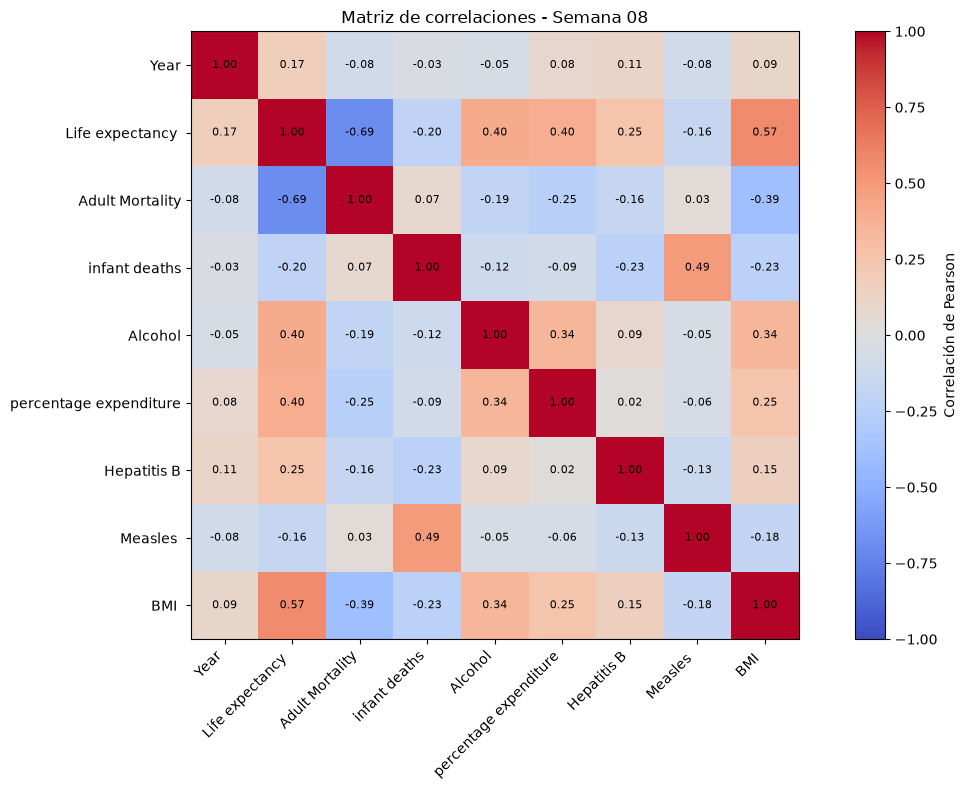

In [34]:

# Paso 4.1: Mapa de calor de correlaciones

fig, ax = plt.subplots(figsize=(12, 8))

imagen = ax.imshow(
    matriz_correlacion,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

# Nombres de las variables
ax.set_xticks(range(len(matriz_correlacion.columns)))
ax.set_yticks(range(len(matriz_correlacion.columns)))

ax.set_xticklabels(
    matriz_correlacion.columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(matriz_correlacion.columns)

# Mostrar los coeficientes dentro de la matriz
for i in range(len(matriz_correlacion)):
    for j in range(len(matriz_correlacion.columns)):
        valor = matriz_correlacion.iloc[i, j]

        ax.text(
            j, i,
            f"{valor:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(imagen, ax=ax, label="Correlación de Pearson")

ax.set_title("Matriz de correlaciones - Semana 08")

plt.tight_layout()
plt.show()


In [35]:

# Paso 5: Preparación de datos para regresión múltiple

variable_objetivo = "Life expectancy"

variables_predictoras = [
    "Adult Mortality",
    "infant deaths",
    "Alcohol",
    "percentage expenditure",
    "Hepatitis B",
    "Measles",
    "BMI"
]

# Crear una copia para no modificar el DataFrame original
datos_modelo = df[
    variables_predictoras + [variable_objetivo]
].copy()

print("Dimensiones originales:", datos_modelo.shape)

# Contar registros completos
print(
    "Registros completos:",
    len(datos_modelo.dropna())
)

# Mostrar valores faltantes
display(datos_modelo.isnull().sum())


KeyError: "['Measles', 'BMI', 'Life expectancy'] not in index"

In [ ]:
datos_modelo = df[
    variables_predictoras + [variable_objetivo]
].copy()

In [ ]:

# Diagnóstico: nombres reales de las columnas

print("Columnas disponibles en el DataFrame:")

for columna in df.columns:
    print(repr(columna))


Columnas disponibles en el DataFrame:
'Year'
'Status'
'Life expectancy '
'Adult Mortality'
'infant deaths'
'Alcohol'
'percentage expenditure'
'Hepatitis B'
'Measles '
' BMI '


In [ ]:

# Eliminar espacios al inicio y al final
# de los nombres de las columnas

df.columns = df.columns.str.strip()

# Verificar los nombres corregidos
print("Columnas corregidas:")

for columna in df.columns:
    print(repr(columna))


Columnas corregidas:
'Year'
'Status'
'Life expectancy'
'Adult Mortality'
'infant deaths'
'Alcohol'
'percentage expenditure'
'Hepatitis B'
'Measles'
'BMI'


In [ ]:

# Paso 5.1: Evaluación de registros completos

total = len(datos_modelo)

datos_completos = datos_modelo.dropna().copy()

completos = len(datos_completos)
eliminados = total - completos

porcentaje_eliminado = (eliminados / total) * 100

print("Registros originales:", total)
print("Registros completos:", completos)
print("Registros incompletos:", eliminados)
print(
    "Porcentaje de registros incompletos:",
    round(porcentaje_eliminado, 2), "%"
)


Registros originales: 2720
Registros completos: 2195
Registros incompletos: 525
Porcentaje de registros incompletos: 19.3 %


In [ ]:

# Paso 5.2: Valores faltantes por variable

resumen_faltantes = pd.DataFrame({
    "Valores faltantes": datos_modelo.isnull().sum(),
    "Porcentaje (%)": (
        datos_modelo.isnull().sum()
        / len(datos_modelo) * 100
    )
})

resumen_faltantes = resumen_faltantes.sort_values(
    by="Porcentaje (%)",
    ascending=False
)

display(resumen_faltantes.round(2))


,Valores faltantes,Porcentaje (%)
Hepatitis B,525,19.3
Adult Mortality,0,0.0
Alcohol,0,0.0
infant deaths,0,0.0
percentage expenditure,0,0.0
Measles,0,0.0
BMI,0,0.0
Life expectancy,0,0.0


In [ ]:

# Paso 5.3: División de entrenamiento y prueba

from sklearn.model_selection import train_test_split

# Variables independientes
X = datos_modelo[variables_predictoras]

# Variable dependiente
y = datos_modelo[variable_objetivo]

# Dividir los datos
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))
print("Valores faltantes en entrenamiento:")
display(X_train.isnull().sum())


Registros de entrenamiento: 2176
Registros de prueba: 544
Valores faltantes en entrenamiento:


Adult Mortality             0
infant deaths               0
Alcohol                     0
percentage expenditure      0
Hepatitis B               411
Measles                     0
BMI                         0
dtype: int64

In [ ]:

# Paso 5.4: Imputación por mediana

from sklearn.impute import SimpleImputer

# Crear el imputador
imputador = SimpleImputer(strategy="median")

# Aprender las medianas con entrenamiento
X_train_imputado = pd.DataFrame(
    imputador.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Aplicar las mismas medianas a prueba
X_test_imputado = pd.DataFrame(
    imputador.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Mostrar la mediana aprendida para Hepatitis B
medianas = pd.Series(
    imputador.statistics_,
    index=X_train.columns
)

print("Mediana de Hepatitis B:",
      medianas["Hepatitis B"])

print("\nValores faltantes en entrenamiento:")
display(X_train_imputado.isnull().sum())

print("\nValores faltantes en prueba:")
display(X_test_imputado.isnull().sum())


Mediana de Hepatitis B: 92.0

Valores faltantes en entrenamiento:


Adult Mortality           0
infant deaths             0
Alcohol                   0
percentage expenditure    0
Hepatitis B               0
Measles                   0
BMI                       0
dtype: int64


Valores faltantes en prueba:


Adult Mortality           0
infant deaths             0
Alcohol                   0
percentage expenditure    0
Hepatitis B               0
Measles                   0
BMI                       0
dtype: int64

In [ ]:

# Paso 6: Entrenamiento del modelo

from sklearn.linear_model import LinearRegression

# Crear el modelo
modelo = LinearRegression()

# Entrenar con los datos preparados
modelo.fit(X_train_imputado, y_train)

# Organizar los coeficientes
tabla_coeficientes = pd.DataFrame({
    "Variable": X_train_imputado.columns,
    "Coeficiente": modelo.coef_
})

# Mostrar resultados
print("Intercepto del modelo:")
print(round(modelo.intercept_, 4))

print("\nCoeficientes de regresión:")
display(tabla_coeficientes.round(4))


Intercepto del modelo:
67.4279

Coeficientes de regresión:


,Variable,Coeficiente
0,Adult Mortality,-0.0395
1,infant deaths,-0.0014
2,Alcohol,0.3793
3,percentage expenditure,0.0007
4,Hepatitis B,0.0180
5,Measles,-0.0001
6,BMI,0.1230


In [ ]:

# Paso 7: Evaluación de la regresión múltiple

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Predecir utilizando los datos de prueba
y_pred = modelo.predict(X_test_imputado)

# Calcular métricas
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

# Mostrar resultados
print("RESULTADOS DEL MODELO")
print("-----------------------------")
print(f"MAE: {mae:.4f} años")
print(f"RMSE: {rmse:.4f} años")
print(f"R²: {r2:.4f}")

# Comparar valores reales y predichos
comparacion = pd.DataFrame({
    "Esperanza de vida real": y_test,
    "Esperanza de vida predicha": y_pred,
    "Error absoluto": abs(y_test - y_pred)
})

display(comparacion.head(10).round(2))


RESULTADOS DEL MODELO
-----------------------------
MAE: 3.9463 años
RMSE: 5.7321 años
R²: 0.6300


,Esperanza de vida real,Esperanza de vida predicha,Error absoluto
1061,65.0,74.79,9.79
408,52.3,55.72,3.42
2497,65.6,67.46,1.86
2290,69.8,70.22,0.42
1261,71.7,70.84,0.86
1265,68.5,69.14,0.64
387,52.4,59.71,7.31
926,73.9,71.49,2.41
2115,58.4,60.55,2.15
2092,73.7,74.21,0.51


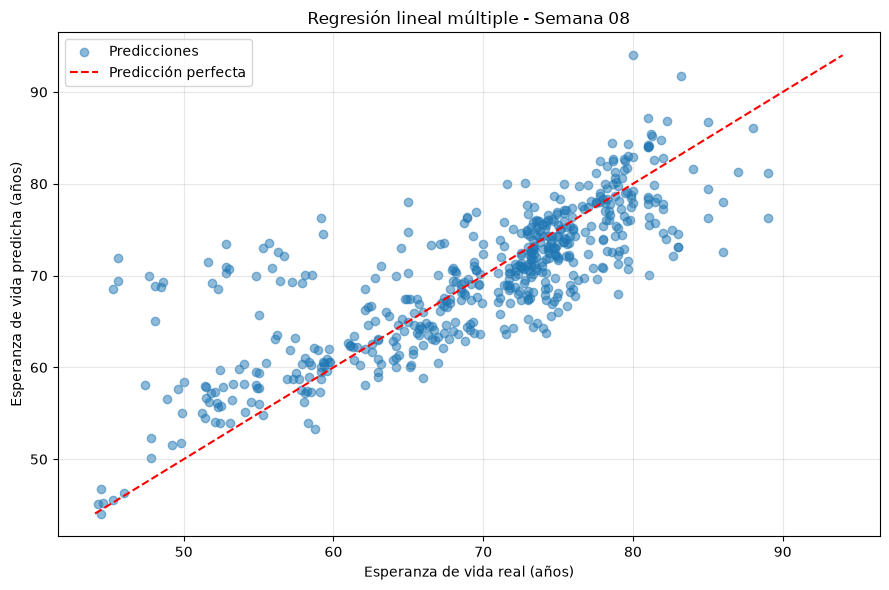

In [ ]:

# Paso 8: Comparación de valores reales y predichos

plt.figure(figsize=(9, 6))

# Puntos de las predicciones
plt.scatter(
    y_test,
    y_pred,
    alpha=0.5,
    label="Predicciones"
)

# Línea de predicción perfecta
limite_min = min(y_test.min(), y_pred.min())
limite_max = max(y_test.max(), y_pred.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    "r--",
    label="Predicción perfecta"
)

plt.xlabel("Esperanza de vida real (años)")
plt.ylabel("Esperanza de vida predicha (años)")
plt.title("Regresión lineal múltiple - Semana 08")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


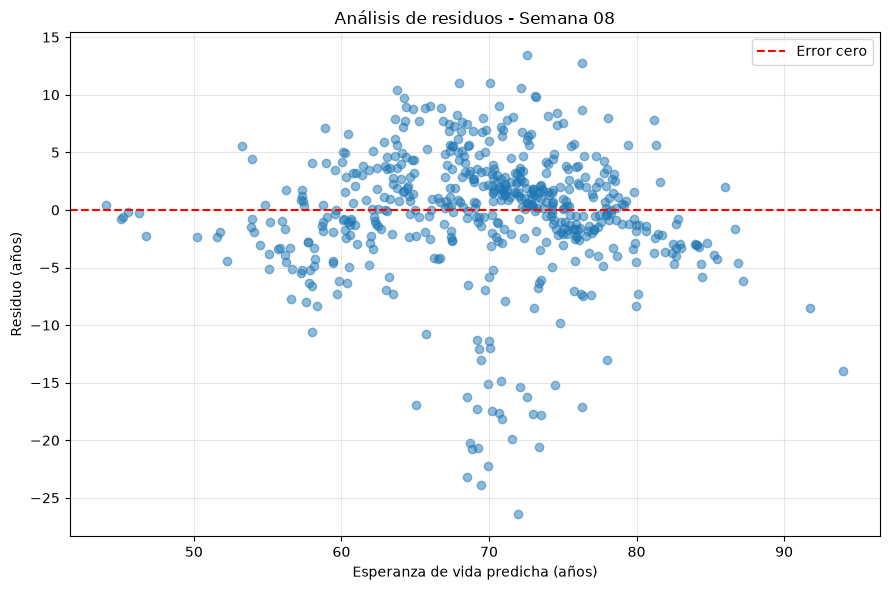

In [ ]:

# Paso 9: Análisis de residuos

residuos = y_test - y_pred

plt.figure(figsize=(9, 6))

plt.scatter(
    y_pred,
    residuos,
    alpha=0.5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Error cero"
)

plt.xlabel("Esperanza de vida predicha (años)")
plt.ylabel("Residuo (años)")
plt.title("Análisis de residuos - Semana 08")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# Paso 9.1: Resumen estadístico de residuos

resumen_residuos = pd.Series(residuos).describe()

print("Resumen estadístico de los residuos:")
display(resumen_residuos.round(4))

print("\nPromedio de los residuos:")
print(round(np.mean(residuos), 4))

print("\nError absoluto máximo:")
print(round(np.max(np.abs(residuos)), 4))


Resumen estadístico de los residuos:


count    544.0000
mean      -0.3147
std        5.7287
min      -26.3653
25%       -2.3200
50%        0.3095
75%        2.8820
max       13.4297
Name: Life expectancy, dtype: float64


Promedio de los residuos:
-0.3147

Error absoluto máximo:
26.3653


In [ ]:


# Paso 10: Identificar los mayores errores

comparacion_errores = pd.DataFrame({
    "Esperanza de vida real": y_test,
    "Esperanza de vida predicha": y_pred,
    "Residuo": residuos,
    "Error absoluto": np.abs(residuos)
})

# Ordenar de mayor a menor error absoluto
mayores_errores = comparacion_errores.sort_values(
    by="Error absoluto",
    ascending=False
).head(5)

print("Las 5 predicciones con mayores errores:")
display(mayores_errores.round(4))


Las 5 predicciones con mayores errores:


,Esperanza de vida real,Esperanza de vida predicha,Residuo,Error absoluto
2309,45.6,71.9653,-26.3653,26.3653
495,45.6,69.4448,-23.8448,23.8448
2155,45.3,68.5132,-23.2132,23.2132
1784,47.7,69.9495,-22.2495,22.2495
509,48.1,68.8471,-20.7471,20.7471


In [ ]:

# Resumen de evaluación del modelo

print(f"MAE: {mae:.4f} años")
print(f"RMSE: {rmse:.4f} años")
print(f"R²: {r2:.4f}")


MAE: 3.9463 años
RMSE: 5.7321 años
R²: 0.6300


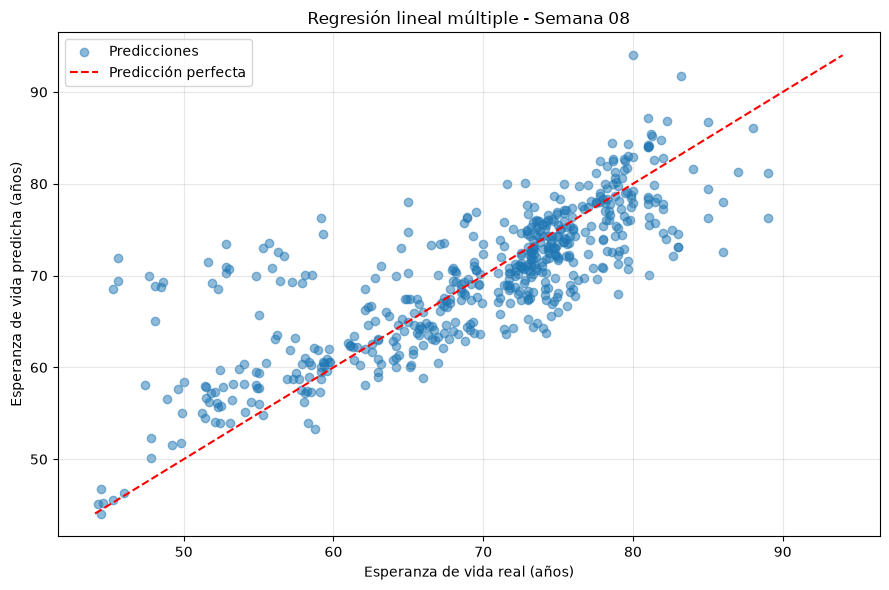

In [ ]:

# Paso 8: Valores reales vs. predichos

plt.figure(figsize=(9, 6))

# Graficar las predicciones
plt.scatter(
    y_test,
    y_pred,
    alpha=0.5,
    label="Predicciones"
)

# Línea de predicción perfecta
minimo = min(y_test.min(), y_pred.min())
maximo = max(y_test.max(), y_pred.max())

plt.plot(
    [minimo, maximo],
    [minimo, maximo],
    "r--",
    label="Predicción perfecta"
)

plt.xlabel("Esperanza de vida real (años)")
plt.ylabel("Esperanza de vida predicha (años)")
plt.title("Regresión lineal múltiple - Semana 08")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


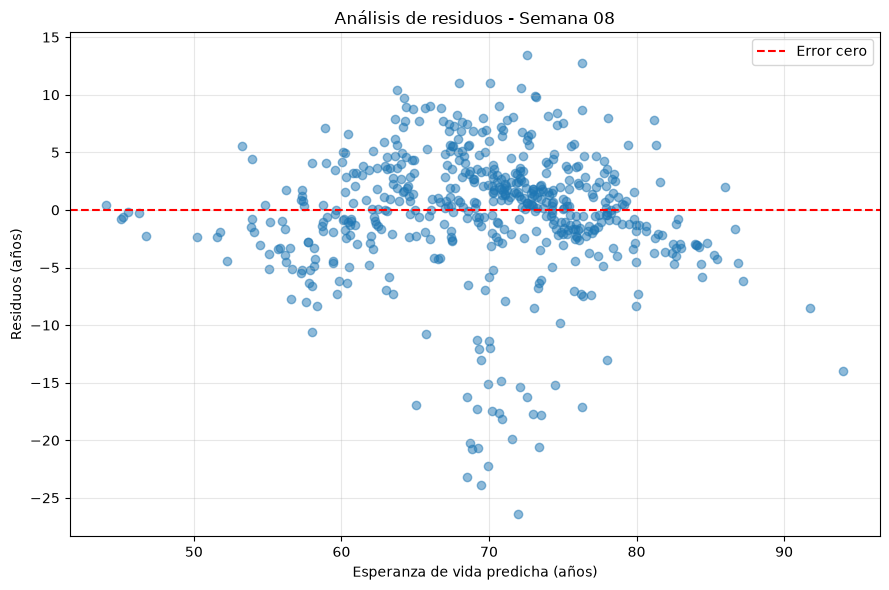

In [ ]:

# Paso 9: Análisis de residuos

# Calcular los residuos
residuos = y_test - y_pred

# Crear la gráfica
plt.figure(figsize=(9, 6))

plt.scatter(
    y_pred,
    residuos,
    alpha=0.5
)

# Línea de referencia: error igual a cero
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Error cero"
)

plt.xlabel("Esperanza de vida predicha (años)")
plt.ylabel("Residuos (años)")
plt.title("Análisis de residuos - Semana 08")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# Paso 10: Resumen final del modelo

resumen_modelo = pd.DataFrame({
    "Indicador": [
        "Registros totales",
        "Registros de entrenamiento",
        "Registros de prueba",
        "Variables predictoras",
        "MAE (años)",
        "RMSE (años)",
        "R²",
        "R² (%)"
    ],
    "Resultado": [
        len(datos_modelo),
        len(X_train),
        len(X_test),
        len(variables_predictoras),
        round(mae, 4),
        round(rmse, 4),
        round(r2, 4),
        round(r2 * 100, 2)
    ]
})

print("RESUMEN DEL MODELO - SEMANA 08")
display(resumen_modelo)


RESUMEN DEL MODELO - SEMANA 08


,Indicador,Resultado
0,Registros totales,2720.0000
1,Registros de entrenamiento,2176.0000
2,Registros de prueba,544.0000
3,Variables predictoras,7.0000
4,MAE (años),3.9463
5,RMSE (años),5.7321
6,R²,0.6300
7,R² (%),63.0000


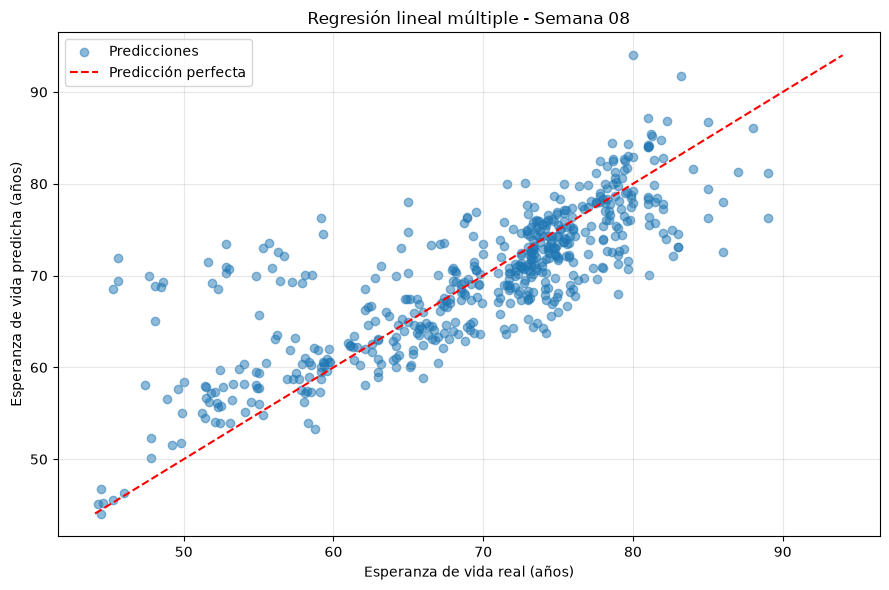

In [ ]:

# Paso 8: Gráfica de valores reales vs. predichos

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5,
    label="Predicciones"
)

# Línea de predicción perfecta
limite_min = min(y_test.min(), y_pred.min())
limite_max = max(y_test.max(), y_pred.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    "r--",
    label="Predicción perfecta"
)

plt.xlabel("Esperanza de vida real (años)")
plt.ylabel("Esperanza de vida predicha (años)")
plt.title("Regresión lineal múltiple - Semana 08")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


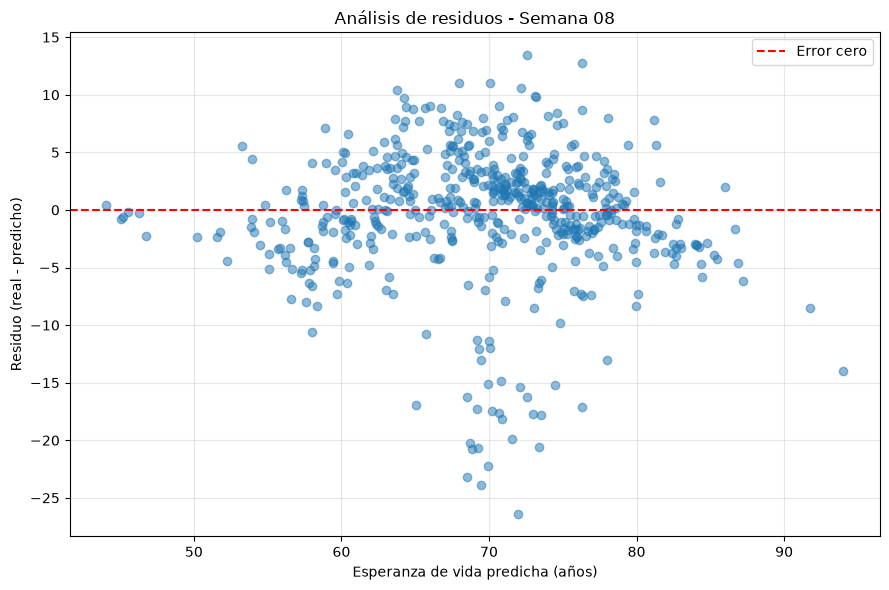

In [ ]:

# Paso 9: Análisis de residuos

residuos = y_test - y_pred

plt.figure(figsize=(9, 6))

plt.scatter(
    y_pred,
    residuos,
    alpha=0.5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Error cero"
)

plt.xlabel("Esperanza de vida predicha (años)")
plt.ylabel("Residuo (real - predicho)")
plt.title("Análisis de residuos - Semana 08")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



## Conclusiones – Reto Semana 08

### 1. Calidad de los datos
Se analizaron 2,720 registros con indicadores
relacionados con la esperanza de vida.

Se identificaron 525 valores faltantes en la
variable Hepatitis B, equivalentes al 19.30 %
de los registros.

Se utilizó imputación por mediana, calculada
exclusivamente con los datos de entrenamiento.
La mediana obtenida fue de 92.0.

### 2. Modelo de regresión lineal múltiple
Se construyó un modelo para estimar la
esperanza de vida utilizando siete variables
predictoras relacionadas con la salud.

Los datos se dividieron en:
- Entrenamiento: 2,176 registros (80 %).
- Prueba: 544 registros (20 %).

### 3. Resultados del modelo
Las métricas obtenidas en prueba fueron:

- MAE: 3.9463 años.
- RMSE: 5.7321 años.
- R²: 0.6300 (63.00 %).

El modelo explica aproximadamente el 63 %
de la variabilidad de la esperanza de vida
en el conjunto de prueba, respecto a la
referencia basada en su media.

### 4. Análisis de errores
Se observaron predicciones cercanas a los
valores reales, pero también errores elevados,
especialmente en algunos registros con
esperanzas de vida bajas.

El análisis de residuos mostró posibles
patrones y dispersión desigual de los errores.

### 5. Conclusión general
La regresión lineal múltiple permitió
identificar asociaciones estadísticas entre
indicadores de salud y esperanza de vida.

El modelo constituye una aproximación inicial
útil, aunque sus predicciones no son exactas.

Como mejoras futuras se recomienda comparar
otros modelos, evaluar nuevas variables,
analizar la multicolinealidad y estudiar
con mayor detalle los errores extremos.

Las asociaciones identificadas no deben
interpretarse como relaciones causales.


In [36]:

# Paso 11: Exportar resultados a Excel

# Crear tabla de predicciones
tabla_predicciones = pd.DataFrame({
    "Esperanza de vida real": y_test,
    "Esperanza de vida predicha": y_pred,
    "Residuo": y_test - y_pred,
    "Error absoluto": abs(y_test - y_pred)
})

# Crear resumen de métricas
tabla_resumen = pd.DataFrame({
    "Indicador": [
        "Registros totales",
        "Registros de entrenamiento",
        "Registros de prueba",
        "Variables predictoras",
        "MAE (años)",
        "RMSE (años)",
        "R²",
        "R² (%)"
    ],
    "Resultado": [
        len(datos_modelo),
        len(X_train),
        len(X_test),
        len(variables_predictoras),
        mae,
        rmse,
        r2,
        r2 * 100
    ]
})

# Crear tabla de coeficientes
tabla_coeficientes_excel = pd.DataFrame({
    "Variable": ["Intercepto"] + variables_predictoras,
    "Coeficiente": [modelo.intercept_] + list(modelo.coef_)
})

# Nombre del archivo de salida
archivo_resultados = "Reto_Semana_08_Resultados.xlsx"

# Exportar las tres hojas
with pd.ExcelWriter(
    archivo_resultados,
    engine="openpyxl"
) as writer:

    tabla_predicciones.round(4).to_excel(
        writer,
        sheet_name="Predicciones",
        index=True,
        index_label="Indice_original"
    )

    tabla_resumen.round(4).to_excel(
        writer,
        sheet_name="Resumen_Modelo",
        index=False
    )

    tabla_coeficientes_excel.round(4).to_excel(
        writer,
        sheet_name="Coeficientes",
        index=False
    )

print("Archivo Excel creado correctamente:")
print(archivo_resultados)


Archivo Excel creado correctamente:
Reto_Semana_08_Resultados.xlsx
